# 3장 · 함수의 반환값·타입 힌트·예외 처리

함수의 반환값은 호출한 쪽에서 다시 계산에 쓸 수 있는 값입니다. 어떤 입력을 받을지, 처리할 수 없는 입력을 만나면 어떤 예외를 낼지도 함께 설계합니다.

공부 시간을 입력하는 칸에는 ‘ 30 ’처럼 공백이 낀 숫자도, ‘내일’ 같은 글자도 들어옵니다. 변환 규칙을 함수 한 곳에 모으고, 실패한 입력을 받은 화면에서 어떻게 안내할지 정합니다.

실행을 확인한 커널은 Python 3.12.15입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 과제 셀에 직접 코드를 작성한 뒤 바로 아래에서 풀이를 펼쳐 보세요.


## print()와 return의 차이

함수 안에서 결과를 출력하는 것과 결과를 호출한 곳으로 돌려주는 일은 따로 일어납니다. 다음 계산에 쓸 값은 return으로 보냅니다.

**print()의 출력과 return의 전달**　인쇄된 30과 다음 계산기로 들어가는 표의 도착지를 비교하세요. Python에서 화면에 값을 인쇄하는 일과 호출자에게 값을 돌려주는 일은 별개입니다.

[웹 교재에서 열기](https://langchain-lecture.vercel.app/chapter03/index.html#concept-clip)


### 셀 01 · print()만 호출한 함수의 반환값

show_minutes가 30을 화면에 쓴 뒤 saved에는 무엇이 남을까요?


In [1]:
def show_minutes(text):
    print(int(text))

saved = show_minutes("30")
print(saved)

30
None


첫 줄의 30은 함수 안에서 찍혔습니다. 두 번째 줄의 None은 return 없이 끝난 함수가 돌려준 값입니다.


### 셀 02 · return과 int() 형 변환

앞뒤 공백을 지우고 정수로 변환한 다음 허용 범위를 확인합니다.


In [2]:
def parse_minutes(text: str) -> int:
    minutes = int(text.strip())
    if minutes < 0 or minutes > 480:
        raise ValueError("분은 0~480 사이여야 합니다.")
    return minutes

print(parse_minutes(" 30 ") + 10)

40


함수가 정수 30을 반환했으므로 10을 더하면 40이 됩니다. -> int는 반환값의 의도를 알려 주고, 범위는 if 문에서 직접 검사합니다.


### 함수의 매개변수와 return

<p>def는 함수 이름과 매개변수를 정해 처리 내용을 묶습니다. 정의만으로는 본문이 실행되지 않습니다. add_minutes(25, 35)처럼 호출할 때 25와 35가 first·second에 전달됩니다. 호출하며 넘긴 값은 인자라고 부릅니다.</p>

<p>return은 결과를 호출한 자리로 돌려주고 해당 함수 실행을 끝냅니다. print는 화면에 보여 줄 뿐 호출자에게 계산 결과를 돌려주는 역할을 하지 않습니다. return을 쓰지 않은 함수의 반환값은 None입니다.</p>

<p>함수 안에서 만든 result는 그 호출 안에서 사용하는 지역 변수입니다. 함수 밖에서는 combined처럼 반환값을 저장한 이름을 사용합니다.</p>

<h3>같은 30분을 출력할 때와 돌려줄 때</h3>

<p>셀 01과 셀 02를 비교합니다. 화면에 찍힌 값과 호출한 쪽이 받은 값을 따로 보세요.</p>

<article><small>STEP 01 · 셀 01</small><h4>함수 내부의 print()</h4>
<p>show_minutes가 문자열을 정수로 바꾸고 화면에 씁니다.</p><pre>show_minutes("30")
화면: 30</pre></article>

<article><small>STEP 02 · 셀 01</small><h4>명시적 return이 없을 때의 None</h4>
<p>함수 끝에 return이 없어 saved에는 None이 들어갑니다.</p><pre>saved = None
print(saved) → None</pre></article>

<article><small>STEP 03 · 셀 02</small><h4>return으로 정수 전달</h4>
<p>parse_minutes는 공백을 지우고 범위를 확인한 뒤 정수 30을 돌려줍니다.</p><pre>parse_minutes(" 30 ") → 30</pre></article>

<article><small>STEP 04 · 셀 02</small><h4>반환값의 산술 연산</h4>
<p>호출한 쪽이 30에 10을 더해 출력합니다.</p><pre>print(30 + 10) → 40</pre></article>


## raise와 try/except로 ValueError 처리

화면에 어떤 안내를 띄울지는 함수를 호출한 쪽에서 정합니다. 계산 함수는 잘못된 입력으로 계속 진행하지 않도록 예외를 올립니다.

<!-- lesson-visual detail-exception -->
**480은 반환하고 481은 예외가 되는 경계**

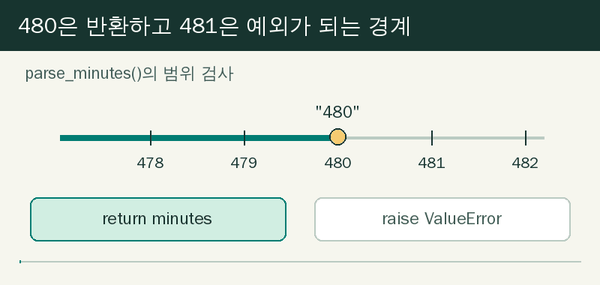

0~480분을 허용하는 parse_minutes()에 두 값을 차례로 넣는 비교입니다. 480은 return에 도달하고, 481은 raise에서 호출한 쪽의 except로 넘어갑니다.
<!-- /lesson-visual detail-exception -->


### 셀 03 · try/except로 ValueError 처리

이번에는 정수 변환은 성공하고 범위 검사에서 멈춥니다.


In [3]:
try:
    parse_minutes("481")
except ValueError as error:
    print(error)

분은 0~480 사이여야 합니다.


‘분은 0~480 사이여야 합니다.’라는 문구가 나옵니다. raise가 실행되면 return까지 가지 않고 호출자의 except로 이동합니다.


### ValueError를 받는 호출자

<p>함수 안에서 raise ValueError(...)가 실행되면 그 함수의 나머지 줄은 건너뜁니다. 호출한 쪽의 try 블록에서 예외가 발생한 위치를 찾고, except ValueError가 어떤 메시지를 출력하는지 이어서 읽어 보세요.</p>


### 과제 04 · 허용 범위의 경계 테스트

480을 넣어 반환값이 정수 480인지 assert로 확인하고 그 값을 표시하세요.

assert 뒤에는 참이어야 하는 조건을 씁니다. 조건이 참이면 다음 줄로 넘어가고 거짓이면 AssertionError에서 멈춥니다. 성공할 때 assert 자체는 아무것도 출력하지 않습니다.


In [4]:
# parse_minutes에 경곗값을 넣어 보세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>minutes = parse_minutes(&quot;480&quot;)
assert minutes == 480
print(minutes)</code></pre>
<p>실행 결과</p><pre><code>480</code></pre>
<p>480이 보이면 assert를 통과했습니다. ‘480 이상’을 막도록 조건을 잘못 바꾸면 허용해야 할 480에서도 예외가 납니다.</p>
</details>


### 정상값·경곗값·예외 테스트

<p>assert 뒤의 조건이 거짓이면 AssertionError가 발생합니다. 정답을 눈으로 보는 대신 예상 결과를 코드에 적어 바뀐 동작을 빠르게 찾습니다. assert는 개발용 검사에 사용하며 운영 입력 검증은 앞서 작성한 if와 raise로 유지합니다. Python 최적화 옵션에서는 assert가 생략될 수 있습니다.</p>

<p>실패 검사는 오류가 발생해야 통과합니다. except의 pass는 이 실패가 예상됐다는 뜻입니다. else로 들어왔다는 것은 거부해야 할 입력이 통과했다는 뜻이므로 AssertionError를 냅니다. pytest로 검사를 모으는 방법은 7장에서 배웁니다.</p>


## 타입 힌트와 입력 정규화 함수

제목 안에 붙은 여러 공백은 한 칸으로 합치고, 시간은 앞에서 만든 함수에 맡깁니다. 두 함수는 키보드나 파일 없이 문자열만 주면 확인할 수 있습니다.


### 타입 힌트와 입력 검증

<p>title: str은 문자열을 받을 의도, -&gt; str은 문자열을 반환할 의도를 나타내는 타입 힌트입니다. 실행기가 이 표기만 보고 값을 자동 변환하거나 잘못된 타입을 모두 막지는 않습니다. 입력 규칙과 검사 코드를 함께 작성해야 합니다.</p>

<p>normalize_title은 공백으로 나눈 단어들을 공백 하나로 다시 합칩니다. " ".join(목록)은 문자열 목록 사이에 공백을 넣어 연결합니다. parse_minutes는 정수로 바꾼 뒤 이 수업 예제의 허용 범위인 0~480분인지 확인합니다. 이 범위는 Python의 제한이 아니라 과제 규칙입니다.</p>

<table><caption>함수별 입출력 계약</caption><thead><tr><th scope="col">함수</th><th scope="col">허용 입력</th><th scope="col">결과·실패</th></tr>
</thead><tbody><tr><td>normalize_title</td><td>문자열</td><td>공백을 정리한 문자열, 빈 입력이면 빈 문자열</td></tr>
<tr><td>parse_minutes</td><td>정수를 나타내는 문자열</td><td>0~480 정수; 변환 실패·범위 밖이면 ValueError</td></tr>
</tbody></table>


### 셀 05 · split()과 join()으로 공백 정리

split에 구분자를 주지 않으면 연속된 공백을 건너뜁니다.


In [5]:
def normalize_title(title: str) -> str:
    return " ".join(title.split())

print(normalize_title("  Python   기초 "))

Python 기초


Python과 기초 사이에 공백 한 칸만 남습니다. strip만 쓰면 양 끝은 정리돼도 가운데 세 칸이 남습니다.


### 문자열 정리와 화면 출력 분리

<p>normalize_title은 정리한 문자열을 돌려주고 화면 출력은 호출한 쪽의 print가 맡습니다. 따라서 같은 함수의 반환값을 그대로 표시할 수도 있고, 다른 함수의 인자로 넘길 수도 있습니다.</p>


### 과제 06 · 변환 실패 예외 처리

‘내일’을 넣으면 정수 변환에 실패하고, ‘481’을 넣으면 범위 검사에 걸립니다. 두 경우 모두 ‘0~480 사이의 정수를 입력하세요.’라고 출력하세요. 입력을 고칠 기회를 주기 위해 실패한 값을 0분으로 저장하지 않습니다.


In [6]:
text = "내일"
# 입력을 검사하고 예외를 처리하세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>text = &quot;내일&quot;
try:
    print(parse_minutes(text))
except ValueError:
    print(&quot;0~480 사이의 정수를 입력하세요.&quot;)</code></pre>
<p>실행 결과</p><pre><code>0~480 사이의 정수를 입력하세요.</code></pre>
<p>text를 &quot;481&quot;로 바꾸면 같은 안내가 나옵니다. &quot;480&quot;으로 바꾸면 parse_minutes가 돌려준 480이 출력됩니다.</p>
</details>


### 숫자가 아닌 문자열 처리하기

<p>text에 들어 있는 ‘내일’은 int로 바꿀 수 없습니다. parse_minutes(text)를 try 안에서 호출하고 except ValueError에서 사용자가 고쳐야 할 입력을 안내해 보세요.</p>


## 돌아보기

‘ 0 ’과 ‘-1’을 각각 넣어 보세요. 하나는 정수 0을 돌려주고 하나는 범위에서 걸립니다. 함수에서 돌려줄 값과 호출자에게 알려 줄 실패를 종이에 한 줄씩 써 보면 다음 장에서 객체를 만들 때도 같은 입력 규칙을 재사용할 수 있습니다.

### 같은 30분을 출력할 때와 돌려줄 때

**함수 안에서 출력**　show_minutes가 문자열을 정수로 바꾸고 화면에 씁니다.

```
show_minutes("30")
화면: 30
```

**호출자가 받은 값**　함수 끝에 return이 없어 saved에는 None이 들어갑니다.

```
saved = None
print(saved) → None
```

**함수가 값 반환**　parse_minutes는 공백을 지우고 범위를 확인한 뒤 정수 30을 돌려줍니다.

```
parse_minutes(" 30 ") → 30
```

**반환값으로 계산**　호출한 쪽이 30에 10을 더해 출력합니다.

```
print(30 + 10) → 40
```
